In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ase.io import write
from ase.visualize import view
from arcskin.make_neb_endpoints import make_endpoints
import pandas as pd

possible_paths = {0: {'reactants': ['O=S(=O)=O', 'O'], 'products': ['O=S=O', 'OO'], 'reactants_energies': [-16980.83054728788, -2081.0465410080456], 'products_energies': [-14933.34580738717, -4126.563266182274], 'diff': np.float64(1.9680147264807601)}, 1: {'reactants': ['O=S(=O)=O', 'O'], 'products': ['O=S=O', '[OH]', '[OH]'], 'reactants_energies': [-16980.83054728788, -2081.0465410080456], 'products_energies': [-14933.34580738717, -2059.4313946648535, -2059.4313946648535], 'diff': np.float64(9.668491579046531)}, 2: {'reactants': ['O=S(=O)=O', 'O'], 'products': ['OO[S@](=O)O'], 'reactants_energies': [-16980.83054728788, -2081.0465410080456], 'products_energies': [-19059.928917438057], 'diff': np.float64(1.948170857867808)}, 3: {'reactants': ['O=S(=O)=O', 'O'], 'products': ['[OH]', '[O]S(=O)O'], 'reactants_energies': [-16980.83054728788, -2081.0465410080456], 'products_energies': [-2059.4313946648535, -16995.138381407873], 'diff': np.float64(7.307312223198096)}, 4: {'reactants': ['O=S(=O)=O', 'O'], 'products': ['[OH]', '[O]SOO'], 'reactants_energies': [-16980.83054728788, -2081.0465410080456], 'products_energies': [-2059.4313946648535, -16994.291466310904], 'diff': np.float64(8.154227320166683)}, 5: {'reactants': ['O=S(=O)=O', 'O'], 'products': ['[O]O', '[O]SO'], 'reactants_energies': [-16980.83054728788, -2081.0465410080456], 'products_energies': [-4106.682936928662, -14947.518029763789], 'diff': np.float64(7.676121603475622)}}


In [2]:
pd.DataFrame(possible_paths).T

,reactants,products,reactants_energies,products_energies,diff
0,"[O=S(=O)=O, O]","[O=S=O, OO]","[-16980.830547, -2081.046541]","[-14933.345807, -4126.563266]",1.968015
1,"[O=S(=O)=O, O]","[O=S=O, [OH], [OH]]","[-16980.830547, -2081.046541]","[-14933.345807, -2059.431395, -2059.431395]",9.668492
2,"[O=S(=O)=O, O]",[OO[S@](=O)O],"[-16980.830547, -2081.046541]",[-19059.928917],1.948171
3,"[O=S(=O)=O, O]","[[OH], [O]S(=O)O]","[-16980.830547, -2081.046541]","[-2059.431395, -16995.138381]",7.307312
4,"[O=S(=O)=O, O]","[[OH], [O]SOO]","[-16980.830547, -2081.046541]","[-2059.431395, -16994.291466]",8.154227
5,"[O=S(=O)=O, O]","[[O]O, [O]SO]","[-16980.830547, -2081.046541]","[-4106.682937, -14947.51803]",7.676122


In [3]:
from arcskin.nanoreactor_run import smiles_to_atoms
from ase.visualize import view 

view(
    smiles_to_atoms("OO[S@](=O)O")[0],viewer="x3d"
)

In [4]:
reactants, products = make_endpoints(
    possible_paths[0]["reactants"], possible_paths[0]["products"], shift=2
)


O=S(=O)=O + O -> O=S=O + OO | form: ['O0-O4', 'O0-H5']  break: ['O0-S1', 'O4-H5']


In [5]:
pd.DataFrame([reactants.info,products.info],index=["reactants","products"]).T

,reactants,products
charge,0,0
mult,1,1
n_radicals,0,0
smiles,"[O=S(=O)=O, O]","[O=S=O, OO]"
formed,"[(0, 4), (0, 5)]","[(0, 4), (0, 5)]"
broken,"[(0, 1), (4, 5)]","[(0, 1), (4, 5)]"


In [6]:
view(reactants,viewer="x3d")

In [7]:
view(products,viewer="x3d")

In [8]:
from arcskin.make_neb_endpoints import make_endpoints

reaction_endpoints = {}
for k,v in possible_paths.items():
    try:
        reactants, products = make_endpoints(v["reactants"],v["products"],shift=2)
        reaction_endpoints[k] = {
            "reactants":reactants,
            "products":products,
            "overall":possible_paths[k]
                                 }
    except Exception:
        print(f"{k} failed")
        pass

O=S(=O)=O + O -> O=S=O + OO | form: ['O0-O4', 'O0-H5']  break: ['O0-S1', 'O4-H5']
O=S(=O)=O + O -> O=S=O + [OH] + [OH] | form: ['O0-H5']  break: ['O0-S1', 'O4-H5']
O=S(=O)=O + O -> OO[S@](=O)O | form: ['O0-O4', 'O2-H5']  break: ['O4-H5']
O=S(=O)=O + O -> [OH] + [O]S(=O)O | form: ['O0-H5']  break: ['O4-H5']
O=S(=O)=O + O -> [OH] + [O]SOO | form: ['O0-O2', 'O0-H5']  break: ['O0-S1', 'O4-H5']
O=S(=O)=O + O -> [O]O + [O]SO | form: ['O0-O4', 'O2-H5']  break: ['O0-S1', 'O4-H5']


In [9]:
from arcskin.run_neb import run_all

results = run_all(reaction_endpoints,n_images=3)

Warp 1.18.0 initialized:
   CUDA not enabled in this build
   Devices:
     "cpu"      : "arm"
   Kernel cache:
     /Users/badw/Library/Caches/warp/1.18.0
running with aimnet


In [18]:
results.T[3]["nebfit"]

{'path': [0,
  np.float64(0.057155707692791734),
  np.float64(0.11427604732074587),
  np.float64(0.1713926237338031),
  np.float64(0.22856068030793847)],
 'energies': array([ 0.        , -0.00185442, -0.00302212, -0.00355335, -0.00331901]),
 'fit_path': array([0.        , 0.00285779, 0.00571557, 0.00857336, 0.01143114,
        0.01428893, 0.01714671, 0.0200045 , 0.02286228, 0.02572007,
        0.02857785, 0.03143564, 0.03429342, 0.03715121, 0.040009  ,
        0.04286678, 0.04572457, 0.04858235, 0.05144014, 0.05429792,
        0.05715571, 0.06001172, 0.06286774, 0.06572376, 0.06857978,
        0.07143579, 0.07429181, 0.07714783, 0.08000384, 0.08285986,
        0.08571588, 0.08857189, 0.09142791, 0.09428393, 0.09713995,
        0.09999596, 0.10285198, 0.105708  , 0.10856401, 0.11142003,
        0.11427605, 0.11713188, 0.1199877 , 0.12284353, 0.12569936,
        0.12855519, 0.13141102, 0.13426685, 0.13712268, 0.13997851,
        0.14283434, 0.14569016, 0.14854599, 0.15140182, 0.15425765,

In [13]:
import pickle 
with open("test.p","wb") as f:
    pickle.dump(results,f)

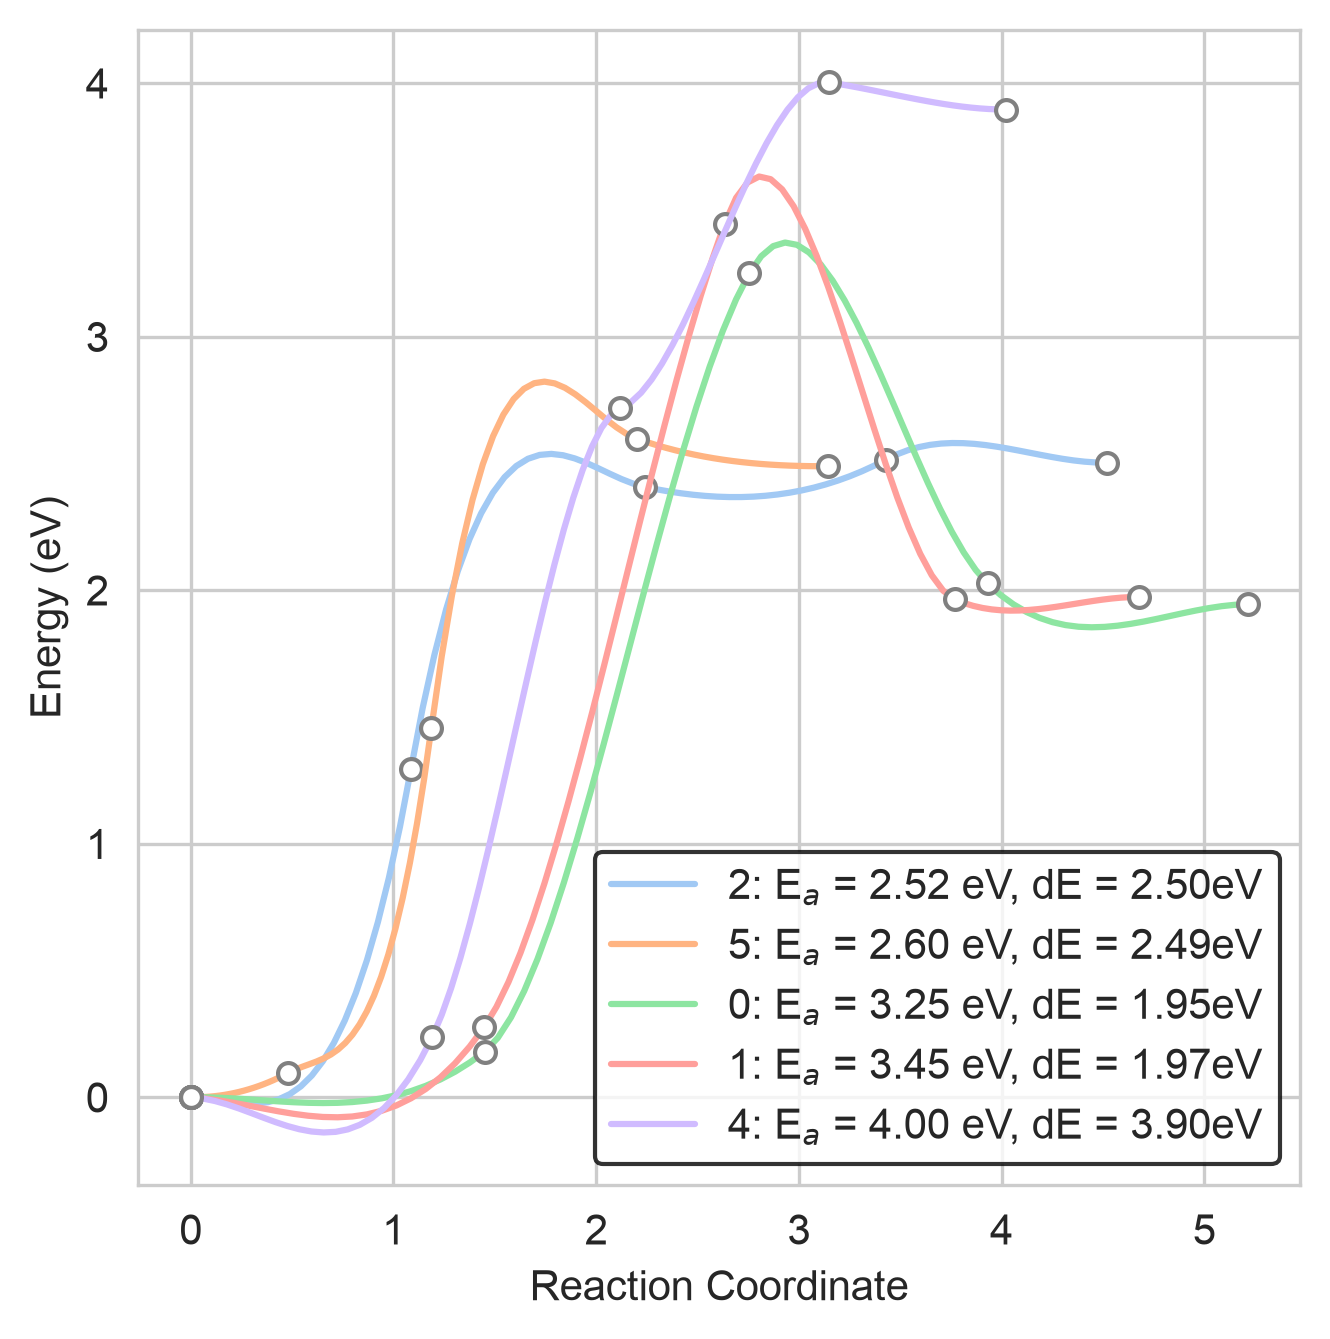

In [23]:
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import collections 

sns.set_style('whitegrid')
sns.set_palette('pastel')

def plot_nebruns(image_dict,ax,**kws):
    for k,v in image_dict.items():
        if v["sane"]:
            fit = v["nebfit"]
            Ef = fit["energies"].max()
            ax.plot(fit["fit_path"],fit["fit_energies"],label=f'{k}: E$_a$ = {Ef :.2F} eV, dE = {v["dE"]:.2F}eV')
            ax.plot(fit["path"],fit["energies"],**kws)

kws = {'marker':'o',
       'linestyle':'None',
       'color':'grey',
       'markerfacecolor':'white',
       'markersize':5}

fig,ax = plt.subplots(ncols=1,nrows=1,figsize=(5,5),dpi=300,sharey=True,sharex=True)
plot_nebruns(image_dict=results.T,ax=ax,**kws)
ax.set_ylabel('Energy (eV)')
ax.set_xlabel('Reaction Coordinate')
    #flat_ax[i].set_title(f"expansion={nebbys[i]["expansion"]},rattle={nebbys[i]["rattle"]},nimages={nebbys[i]["nimages"]}")
ax.legend(edgecolor="black")